<a href="https://colab.research.google.com/github/polinaburlacheva-eng/python-data-lab1/blob/main/Google_colabLab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Работа с Google Colab

В данном блокноте проверяется версия Python, устанавливаются и проверяются
библиотеки pandas и polars, загружается срез собственного набора данных,
проводится его первичный анализ и строится график.

In [1]:
import sys

print("Версия Python:", sys.version)

Версия Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


### Сравнение версии Python

В Google Colab используется версия Python 3.13.16.
Требуемая версия в курсе — Python 3.12.14.
Таким образом, в Colab используется более новая версия Python.

In [2]:
!pip install pandas polars

In [3]:
import pandas
import polars

print("pandas:", pandas.__version__)
print("polars:", polars.__version__)

pandas: 2.2.3
polars: 1.35.2


Загрузка среза набора данных

На данном этапе в сеанс Google Colab загружается отладочный срез
набора данных, подготовленный для лабораторной работы.

In [4]:
from google.colab import files

uploaded = files.upload()

Saving all_games.csv to all_games.csv


Чтение набора данных

Загруженный CSV-файл считывается с помощью библиотеки pandas в DataFrame
для дальнейшего анализа.

In [5]:
import pandas as pd

df = pd.read_csv("all_games.csv")

df.head()

/tmp/ipykernel_660/1214318113.py:3: DtypeWarning: Columns (4,7,10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("all_games.csv")


,PlayNum,GameID,Date,Period,Possession,Time,AwayName,AwayScore,AwayEvent,HomeName,...,A1,A2,A3,A4,A5,H1,H2,H3,H4,H5
0,0,201011240MIN,11/24/2010,1,0.0,12:00.0,SAS,0,Start of 1st quarter,MIN,...,blairde01,jefferi01,parketo01,duncati01,ginobma01,loveke01,johnswe01,milicda01,ridnolu01,beaslmi01
1,1,201011240MIN,11/24/2010,1,0.0,12:00.0,SAS,0,Jump ball: D. Miličić vs. T. Duncan (K. Love g...,MIN,...,blairde01,jefferi01,parketo01,duncati01,ginobma01,loveke01,johnswe01,milicda01,ridnolu01,beaslmi01
2,2,201011240MIN,11/24/2010,1,1.0,11:44.0,SAS,0,NaN,MIN,...,blairde01,jefferi01,parketo01,duncati01,ginobma01,loveke01,johnswe01,milicda01,ridnolu01,beaslmi01
3,3,201011240MIN,11/24/2010,1,2.0,11:30.0,SAS,2,R. Jefferson makes 2-pt dunk from 1 ft (assist...,MIN,...,blairde01,jefferi01,parketo01,duncati01,ginobma01,loveke01,johnswe01,milicda01,ridnolu01,beaslmi01
4,4,201011240MIN,11/24/2010,1,3.0,11:11.0,SAS,2,NaN,MIN,...,blairde01,jefferi01,parketo01,duncati01,ginobma01,loveke01,johnswe01,milicda01,ridnolu01,beaslmi01


In [6]:
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

Количество строк: 200000
Количество столбцов: 27


Столбцы и типы данных

Выведем названия всех столбцов набора данных и тип данных, который
используется для хранения значений в каждом столбце.

In [7]:
for column in df.columns:
    print(column, "—", df[column].dtype)

PlayNum — int64
GameID — object
Date — object
Period — int64
Possession — object
Time — object
AwayName — object
AwayScore — object
AwayEvent — object
HomeName — object
HomeScore — object
HomeEvent — object
AwayIn — object
AwayOut — object
HomeIn — object
HomeOut — object
ActivePlayers — object
A1 — object
A2 — object
A3 — object
A4 — object
A5 — object
H1 — object
H2 — object
H3 — object
H4 — object
H5 — object


Доля пропущенных значений

Для каждого столбца вычислим долю пропущенных значений от общего количества
строк в наборе данных.

In [8]:
missing_share = df.isna().mean() * 100

print("Доля пропусков по столбцам (%):")
print(missing_share)

Доля пропусков по столбцам (%):
PlayNum           0.0000
GameID            0.0000
Date              0.0000
Period            0.0000
Possession        0.0000
Time              0.0000
AwayName          0.0000
AwayScore         1.9600
AwayEvent        47.3220
HomeName          0.0000
HomeScore         1.8985
HomeEvent        50.4450
AwayIn           95.4020
AwayOut          95.4045
HomeIn           95.4440
HomeOut          91.6915
ActivePlayers     0.0000
A1                0.0000
A2                0.0000
A3                0.0000
A4                0.0000
A5                0.0000
H1                0.0000
H2                0.0000
H3                0.0000
H4                0.0000
H5                3.9345
dtype: float64


Количество записей по годам

Построим график, показывающий количество записей набора данных для каждого года.
Это позволяет увидеть, как распределены данные по времени.

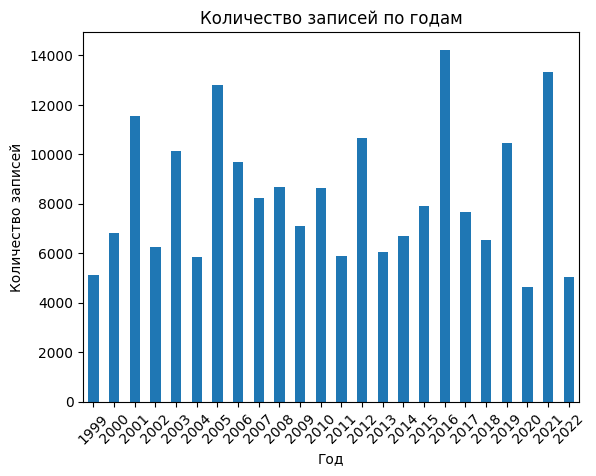

In [9]:
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt

df["Date"] = pd.to_datetime(df["Date"])

year_counts = df["Date"].dt.year.value_counts().sort_index()

year_counts.plot(kind="bar")

plt.title("Количество записей по годам")
plt.xlabel("Год")
plt.ylabel("Количество записей")
plt.xticks(rotation=45)
plt.show()

Вывод

В ходе работы была проверена версия Python в Google Colab и выполнено
сравнение с требуемой версией Python 3.12.14. Были установлены и проверены
библиотеки pandas и polars.

В Colab был загружен отладочный срез собственного набора данных. С помощью
pandas были определены размер набора данных, названия и типы столбцов, а
также доля пропущенных значений.

Для визуального анализа было построено распределение количества записей
по годам на основе столбца Date.